# Citra medis — Klasifikasi (transfer learning ResNet18)
**Kapan dipakai:** rontgen, patologi, atau citra mikroskop dengan label penyakit / bukan.

**Idenya:** CNN yang sudah dilatih di ImageNet (ResNet18) dilatih ulang sebentar pada gambar
medis. Di bidang medis yang penting bukan akurasi saja:
- **sensitivitas** = penyakit yang terdeteksi,
- **spesifisitas** = orang sehat yang dikenali sehat.

Ambang dipilih agar sensitivitas tinggi (jangan melewatkan pasien sakit).

**Langkah:**
1. Baca gambar, lihat contoh.
2. Latih ResNet18 (semua lapisan), bobot kelas untuk data tidak seimbang.
3. Pilih ambang di data valid, submission.

**Data demo:** PneumoniaMNIST (MedMNIST v2, rontgen dada anak 64x64, 0 = normal,
1 = pneumonia, lisensi CC BY 4.0). **Penting:** bila data punya ID pasien, split harus
**per pasien**. MedMNIST sudah membagi per pasien, jadi bagiannya dipakai apa adanya.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, roc_curve
from torch import nn
from torch.nn import functional
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/medis/pneumoniamnist"   # GANTI saat lomba
DATA_NPZ = f"{DATA_FOLDER}/pneumoniamnist_64.npz"
PRETRAINED = "../../pretrained"

IMAGE_SIZE = 128              # gambar diperbesar ke ukuran ini sebelum masuk CNN
EPOCHS = 6
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
TARGET_SENSITIVITY = 0.95     # ambang dipilih: sensitivitas minimal ini di data valid
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406])
MEAN = MEAN.view(1, 3, 1, 1).to(DEVICE)
STD = torch.tensor([0.229, 0.224, 0.225])
STD = STD.view(1, 3, 1, 1).to(DEVICE)
torch.manual_seed(SEED)

## Baca data (npz: gambar uint8 + label)

In [3]:
data = np.load(DATA_NPZ)
train_images = data["train_images"]
y_train = data["train_labels"].ravel()
valid_images = data["val_images"]
y_valid = data["val_labels"].ravel()
test_images = data["test_images"]
y_test = data["test_labels"].ravel()        # kunci jawaban, hanya dipakai di sel terakhir
print(train_images.shape, valid_images.shape, test_images.shape)
print("proporsi pneumonia latih:", round(y_train.mean(), 3), "| valid:", round(y_valid.mean(), 3))

(4708, 64, 64) (524, 64, 64) (624, 64, 64)
proporsi pneumonia latih: 0.742 | valid: 0.742


## EDA: contoh gambar normal vs pneumonia

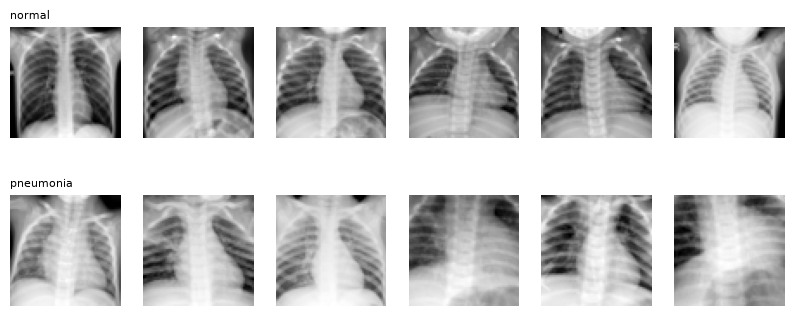

In [4]:
CLASS_NAMES = ["normal", "pneumonia"]
fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for row in [0, 1]:
    examples = train_images[y_train == row]
    for column in range(6):
        axes[row, column].imshow(examples[column], cmap="gray")
        axes[row, column].axis("off")
    axes[row, 0].set_title(CLASS_NAMES[row], fontsize=8, loc="left")
plt.show()

## Model: ResNet18 pretrained, lapisan akhir diganti 2 kelas
Pilih SATU backbone: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [5]:
network = models.resnet18(weights=None)
network.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth", map_location="cpu"))
# network = models.resnet50(weights=None)     # lebih kuat, lebih lambat
# network.load_state_dict(torch.load(f"{PRETRAINED}/resnet50/model.pth", map_location="cpu"))
network.fc = nn.Linear(network.fc.in_features, 2)
network = network.to(DEVICE)

# kelas pneumonia jauh lebih banyak: beri bobot lebih besar ke kelas normal
class_weights = len(y_train) / (2 * np.bincount(y_train))
class_weights = torch.tensor(class_weights, dtype=torch.float32)
loss_function = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
optimizer = torch.optim.Adam(network.parameters(), lr=LEARNING_RATE)

## Latih (loop biasa: tiap epoch lewati semua batch)

In [6]:
def prepare(images_uint8):
    batch = torch.tensor(images_uint8).float()
    batch = batch.to(DEVICE) / 255                       # (B, 64, 64), nilai 0-1
    batch = batch.unsqueeze(1).repeat(1, 3, 1, 1)        # abu-abu -> 3 kanal
    batch = functional.interpolate(batch, size=IMAGE_SIZE, mode="bilinear", align_corners=False)
    return (batch - MEAN) / STD


# coba pada 2 gambar
print(prepare(train_images[:2]).shape)

for epoch in range(EPOCHS):
    network.train()
    order = np.random.default_rng(SEED + epoch).permutation(len(y_train))
    total_loss = 0
    for start in range(0, len(order), BATCH_SIZE):
        rows = order[start:start + BATCH_SIZE]
        labels = torch.tensor(y_train[rows]).long()
        optimizer.zero_grad()
        loss = loss_function(network(prepare(train_images[rows])), labels.to(DEVICE))
        loss.backward()
        optimizer.step()
        total_loss = total_loss + loss.item() * len(rows)
    print("epoch", epoch + 1, "loss:", round(total_loss / len(y_train), 4))

torch.Size([2, 3, 128, 128])


epoch 1 loss: 0.1259


epoch 2 loss: 0.0463


epoch 3 loss: 0.0222


epoch 4 loss: 0.0332


epoch 5 loss: 0.0217


epoch 6 loss: 0.0095


## Peluang pneumonia di data valid dan test

In [7]:
def predict_proba(images_uint8):
    network.eval()
    parts = []
    with torch.no_grad():
        for start in range(0, len(images_uint8), 256):
            outputs = network(prepare(images_uint8[start:start + 256]))
            probabilities = functional.softmax(outputs, dim=1)
            parts.append(probabilities[:, 1].cpu().numpy())
    return np.concatenate(parts)


valid_proba = predict_proba(valid_images)
test_proba = predict_proba(test_images)
print("ROC-AUC valid:", round(roc_auc_score(y_valid, valid_proba), 4))

ROC-AUC valid: 0.9986


## Pilih ambang: sensitivitas tinggi di data valid (ambang terbesar yang masih memenuhi)

In [8]:
threshold = 0.5
for candidate in np.arange(0.01, 1.0, 0.01):
    guesses = (valid_proba >= candidate).astype(int)
    sensitivity = ((guesses == 1) & (y_valid == 1)).sum() / (y_valid == 1).sum()
    if sensitivity >= TARGET_SENSITIVITY:
        threshold = candidate
print("ambang terpilih:", round(threshold, 2))

ambang terpilih: 0.99


## Submission (ambang pilihan)
Saat lomba: ganti `test_images` dengan gambar soal, lalu kolom `id` dari file soal.

In [9]:
predictions = (test_proba >= threshold).astype(int)

submission = pd.DataFrame()
submission["id"] = range(len(predictions))
submission["proba_pneumonia"] = test_proba
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,proba_pneumonia,label
0,0,0.999999,1
1,1,0.999994,1
2,2,0.999991,1
3,3,0.000374,0
4,4,0.999999,1


## Cek dengan kunci jawaban (HAPUS saat lomba)
Bandingkan ambang 0.5 dengan ambang pilihan: sensitivitas naik, spesifisitas turun.

ROC-AUC test: 0.9806
ambang 0.5 | sensitivitas: 1.0 | spesifisitas: 0.624 | F1: 0.899
ambang pilihan | sensitivitas: 0.992 | spesifisitas: 0.833 | F1: 0.949


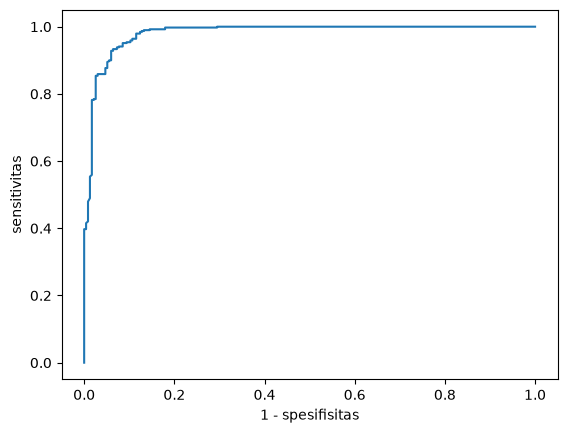

In [10]:
print("ROC-AUC test:", round(roc_auc_score(y_test, test_proba), 4))
for name, value in [("ambang 0.5", 0.5), ("ambang pilihan", threshold)]:
    guesses = (test_proba >= value).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, guesses).ravel()
    print(name, "| sensitivitas:", round(tp / (tp + fn), 3),
          "| spesifisitas:", round(tn / (tn + fp), 3),
          "| F1:", round(f1_score(y_test, guesses), 3))

false_positive_rate, true_positive_rate, _ = roc_curve(y_test, test_proba)
plt.plot(false_positive_rate, true_positive_rate)
plt.xlabel("1 - spesifisitas")
plt.ylabel("sensitivitas")
plt.show()